In [2]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 33.0 MB/s eta 0:00:00


In [3]:
from Bio import Entrez, SeqIO

# Enter your email address for NCBI access
Entrez.email = "abdulmuqeetanas@gmail.com"

# Download human TP53 mRNA reference sequence
handle = Entrez.efetch(
    db="nucleotide",
    id="NM_000546.6",
    rettype="fasta",
    retmode="text"
)

# Read the FASTA sequence
tp53_record = SeqIO.read(handle, "fasta")
handle.close()

# Display sequence information
print("Sequence ID:", tp53_record.id)
print("Description:", tp53_record.description)
print("Sequence Length:", len(tp53_record.seq))
print("First 100 nucleotides:", tp53_record.seq[:100])

Sequence ID: NM_000546.6
Description: NM_000546.6 Homo sapiens tumor protein p53 (TP53), transcript variant 1, mRNA
Sequence Length: 2512
First 100 nucleotides: CTCAAAAGTCTAGAGCCACCGTCCAGGGAGCAGGTAGCTGCTGGGCTCCGGGGACACTTTGCGTTCGGGCTGGGAGCGTGCTTTCCACGACGGTGACACG


In [4]:
from Bio import SeqIO

# Save the TP53 sequence as a FASTA file
SeqIO.write(tp53_record, "TP53_Human_Sequence.fasta", "fasta")

print("TP53 FASTA file saved successfully!")

TP53 FASTA file saved successfully!


In [5]:
from Bio.SeqUtils import gc_fraction

# Get the TP53 sequence
tp53_sequence = tp53_record.seq

# Count each nucleotide
a_count = tp53_sequence.count("A")
t_count = tp53_sequence.count("T")
g_count = tp53_sequence.count("G")
c_count = tp53_sequence.count("C")

# Calculate GC content
gc_content = gc_fraction(tp53_sequence) * 100

# Display results
print("TP53 NUCLEOTIDE ANALYSIS")
print("------------------------")
print("Sequence Length:", len(tp53_sequence))
print("Adenine (A):", a_count)
print("Thymine (T):", t_count)
print("Guanine (G):", g_count)
print("Cytosine (C):", c_count)
print("GC Content:", round(gc_content, 2), "%")

TP53 NUCLEOTIDE ANALYSIS
------------------------
Sequence Length: 2512
Adenine (A): 532
Thymine (T): 639
Guanine (G): 621
Cytosine (C): 720
GC Content: 53.38 %


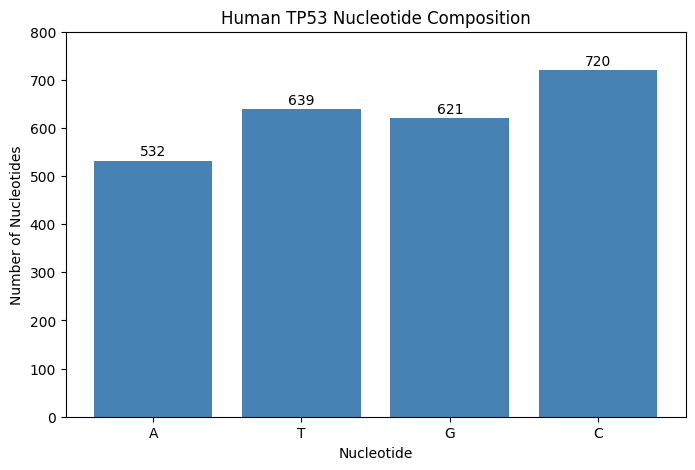

In [6]:
import matplotlib.pyplot as plt

# Nucleotide names and counts
nucleotides = ["A", "T", "G", "C"]
counts = [a_count, t_count, g_count, c_count]

# Create bar graph
plt.figure(figsize=(8, 5))
plt.bar(nucleotides, counts, color="steelblue")

# Add labels
plt.xlabel("Nucleotide")
plt.ylabel("Number of Nucleotides")
plt.title("Human TP53 Nucleotide Composition")

# Display counts above bars
for i, count in enumerate(counts):
    plt.text(i, count + 10, str(count), ha="center")

plt.ylim(0, 800)
plt.show()

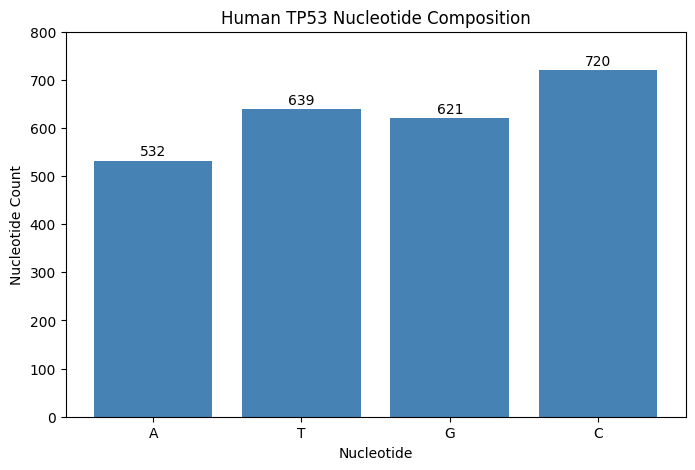

Graph saved successfully!


In [7]:
import matplotlib.pyplot as plt

# Nucleotide names and counts
nucleotides = ["A", "T", "G", "C"]
counts = [a_count, t_count, g_count, c_count]

# Create graph
plt.figure(figsize=(8, 5))
plt.bar(nucleotides, counts, color="steelblue")

# Add labels and title
plt.xlabel("Nucleotide")
plt.ylabel("Nucleotide Count")
plt.title("Human TP53 Nucleotide Composition")

# Add values above each bar
for i, count in enumerate(counts):
    plt.text(i, count + 10, str(count), ha="center")

plt.ylim(0, 800)

# Save graph
plt.savefig("TP53_Nucleotide_Composition.png",
            dpi=300, bbox_inches="tight")

plt.show()

print("Graph saved successfully!")

In [8]:
import pandas as pd

# Store nucleotide counts
data = {
    "Nucleotide": ["A", "T", "G", "C"],
    "Count": [a_count, t_count, g_count, c_count]
}

# Create a DataFrame
df = pd.DataFrame(data)

# Calculate percentage of each nucleotide
df["Percentage"] = (df["Count"] / len(tp53_sequence) * 100).round(2)

# Display results
display(df)

,Nucleotide,Count,Percentage
0,A,532,21.18
1,T,639,25.44
2,G,621,24.72
3,C,720,28.66


In [9]:
df.to_csv("TP53_Nucleotide_Analysis.csv", index=False)

print("TP53 nucleotide analysis CSV saved successfully!")

TP53 nucleotide analysis CSV saved successfully!


In [10]:
# Calculate AT content
at_content = ((a_count + t_count) / len(tp53_sequence)) * 100

# Calculate GC-to-AT ratio
gc_at_ratio = (g_count + c_count) / (a_count + t_count)

# Display results
print("TP53 SEQUENCE STATISTICS")
print("------------------------")
print("Sequence Length:", len(tp53_sequence))
print("GC Content:", round(gc_content, 2), "%")
print("AT Content:", round(at_content, 2), "%")
print("GC-to-AT Ratio:", round(gc_at_ratio, 3))

TP53 SEQUENCE STATISTICS
------------------------
Sequence Length: 2512
GC Content: 53.38 %
AT Content: 46.62 %
GC-to-AT Ratio: 1.145


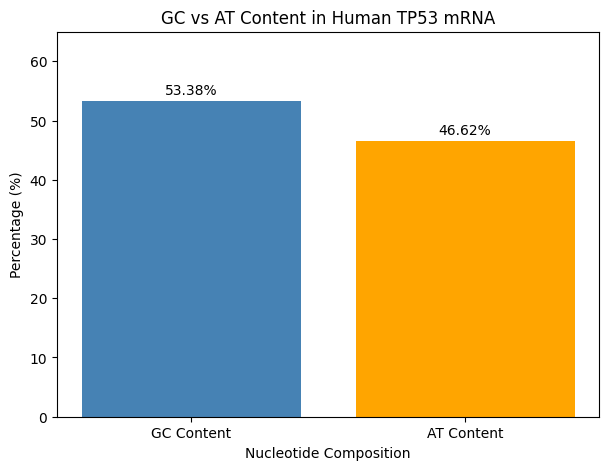

GC vs AT comparison graph saved successfully!


In [11]:
import matplotlib.pyplot as plt

# Create categories and percentages
categories = ["GC Content", "AT Content"]
percentages = [gc_content, at_content]

# Create bar graph
plt.figure(figsize=(7, 5))
plt.bar(categories, percentages, color=["steelblue", "orange"])

# Add labels and title
plt.xlabel("Nucleotide Composition")
plt.ylabel("Percentage (%)")
plt.title("GC vs AT Content in Human TP53 mRNA")

# Display percentages above bars
for i, value in enumerate(percentages):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.ylim(0, 65)

# Save the graph
plt.savefig("TP53_GC_AT_Comparison.png",
            dpi=300, bbox_inches="tight")

# Display graph
plt.show()

print("GC vs AT comparison graph saved successfully!")

In [12]:
from Bio import Entrez, SeqIO

# Download the TP53 GenBank record
handle = Entrez.efetch(
    db="nucleotide",
    id="NM_000546.6",
    rettype="gb",
    retmode="text"
)

tp53_genbank = SeqIO.read(handle, "genbank")
handle.close()

# Display information
print("Sequence ID:", tp53_genbank.id)
print("Sequence Length:", len(tp53_genbank.seq))
print("Number of Features:", len(tp53_genbank.features))

Sequence ID: NM_000546.6
Sequence Length: 2512
Number of Features: 70


In [13]:
# Find the coding sequence (CDS)
for feature in tp53_genbank.features:
    if feature.type == "CDS":

        # Extract the coding DNA sequence
        tp53_cds = feature.extract(tp53_genbank.seq)

        # Get CDS start and end positions
        cds_start = int(feature.location.start) + 1
        cds_end = int(feature.location.end)

        print("TP53 CODING SEQUENCE ANALYSIS")
        print("-----------------------------")
        print("CDS Start Position:", cds_start)
        print("CDS End Position:", cds_end)
        print("CDS Length:", len(tp53_cds))
        print("First 60 Nucleotides:", tp53_cds[:60])

TP53 CODING SEQUENCE ANALYSIS
-----------------------------
CDS Start Position: 143
CDS End Position: 1324
CDS Length: 1182
First 60 Nucleotides: ATGGAGGAGCCGCAGTCAGATCCTAGCGTCGAGCCCCCTCTGAGTCAGGAAACATTTTCA


In [14]:
# Translate TP53 coding sequence into protein
tp53_protein = tp53_cds.translate(to_stop=True)

# Display protein information
print("TP53 PROTEIN ANALYSIS")
print("---------------------")
print("CDS Length:", len(tp53_cds))
print("Protein Length:", len(tp53_protein))
print("Protein Sequence:", tp53_protein)
print("First 50 Amino Acids:", tp53_protein[:50])

TP53 PROTEIN ANALYSIS
---------------------
CDS Length: 1182
Protein Length: 393
Protein Sequence: MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLSPDDIEQWFTEDPGPDEAPRMPEAAPPVAPAPAAPTPAAPAPAPSWPLSSSVPSQKTYQGSYGFRLGFLHSGTAKSVTCTYSPALNKMFCQLAKTCPVQLWVDSTPPPGTRVRAMAIYKQSQHMTEVVRRCPHHERCSDSDGLAPPQHLIRVEGNLRVEYLDDRNTFRHSVVVPYEPPEVGSDCTTIHYNYMCNSSCMGGMNRRPILTIITLEDSSGNLLGRNSFEVRVCACPGRDRRTEEENLRKKGEPHHELPPGSTKRALPNNTSSSPQPKKKPLDGEYFTLQIRGRERFEMFRELNEALELKDAQAGKEPGGSRAHSSHLKSKKGQSTSRHKKLMFKTEGPDSD
First 50 Amino Acids: MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLSPDDI


In [15]:
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO

# Create a protein sequence record
protein_record = SeqRecord(
    tp53_protein,
    id="NP_000537.3",
    description="Human p53 protein translated from TP53 NM_000546.6"
)

# Save the protein sequence as FASTA
SeqIO.write(protein_record, "TP53_Protein_Sequence.fasta", "fasta")

print("TP53 protein FASTA file saved successfully!")

TP53 protein FASTA file saved successfully!


In [16]:
saved_protein = SeqIO.read("TP53_Protein_Sequence.fasta", "fasta")

print("Protein ID:", saved_protein.id)
print("Protein Length:", len(saved_protein.seq))
print("First 50 Amino Acids:", saved_protein.seq[:50])

Protein ID: NP_000537.3
Protein Length: 393
First 50 Amino Acids: MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLSPDDI


In [17]:
import pandas as pd
from collections import Counter

# Count amino acids in the p53 protein
amino_acid_counts = Counter(str(tp53_protein))

# Convert counts into a DataFrame
aa_df = pd.DataFrame(
    amino_acid_counts.items(),
    columns=["Amino Acid", "Count"]
)

# Sort from highest to lowest count
aa_df = aa_df.sort_values(
    by="Count",
    ascending=False
)

# Display results
display(aa_df)

,Amino Acid,Count
2,P,45
4,S,38
7,L,32
1,E,30
16,R,26
13,A,24
15,G,23
8,T,22
11,K,20
5,D,20


In [18]:
print("Total Amino Acids:", aa_df["Count"].sum())
print("Protein Length:", len(tp53_protein))

Total Amino Acids: 393
Protein Length: 393


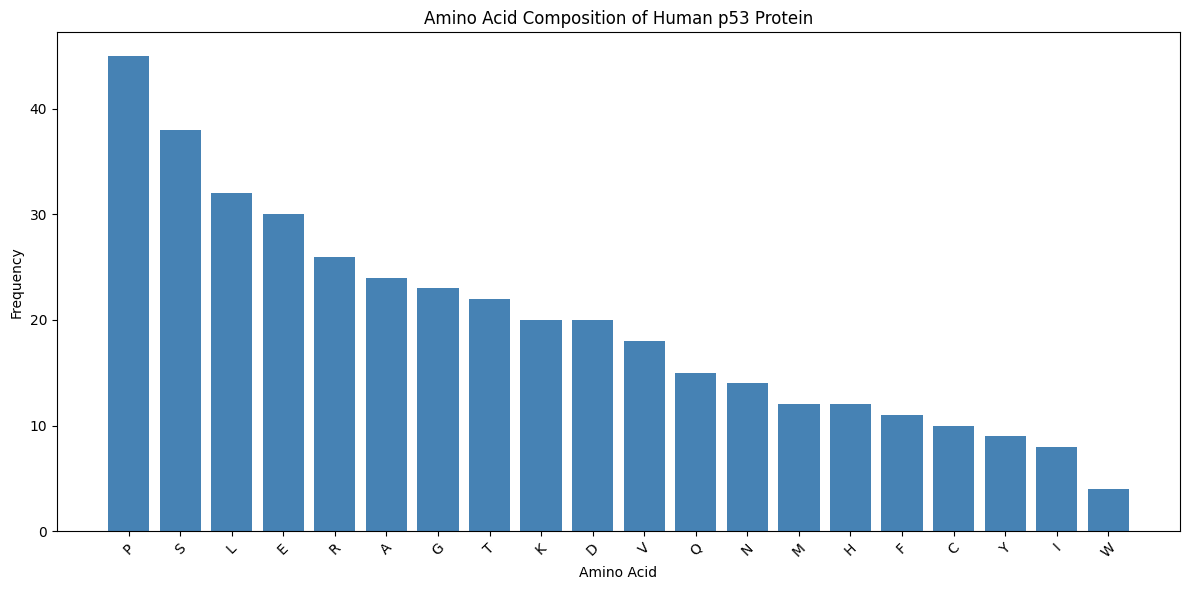

Amino acid composition graph saved successfully!


In [19]:
import matplotlib.pyplot as plt

# Create the graph
plt.figure(figsize=(12, 6))

plt.bar(
    aa_df["Amino Acid"],
    aa_df["Count"],
    color="steelblue"
)

# Add labels and title
plt.xlabel("Amino Acid")
plt.ylabel("Frequency")
plt.title("Amino Acid Composition of Human p53 Protein")

# Rotate labels for readability
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

# Save the graph
plt.savefig(
    "TP53_Amino_Acid_Composition.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the graph
plt.show()

print("Amino acid composition graph saved successfully!")

In [20]:
# Save amino acid composition results
aa_df.to_csv(
    "TP53_Amino_Acid_Composition.csv",
    index=False
)

print("Amino acid composition CSV saved successfully!")

Amino acid composition CSV saved successfully!


In [21]:
# Read the saved CSV file
saved_aa_df = pd.read_csv("TP53_Amino_Acid_Composition.csv")

# Display the results
display(saved_aa_df)

# Verify total amino acids
print("Total Amino Acids:", saved_aa_df["Count"].sum())

,Amino Acid,Count
0,P,45
1,S,38
2,L,32
3,E,30
4,R,26
5,A,24
6,G,23
7,T,22
8,K,20
9,D,20


Total Amino Acids: 393


In [22]:
from Bio import Entrez, SeqIO

# Download the official p53 reference protein
handle = Entrez.efetch(
    db="protein",
    id="NP_000537.3",
    rettype="fasta",
    retmode="text"
)

reference_protein = SeqIO.read(handle, "fasta")
handle.close()

print("Protein ID:", reference_protein.id)
print("Protein Length:", len(reference_protein.seq))
print("First 50 Amino Acids:", reference_protein.seq[:50])

Protein ID: NP_000537.3
Protein Length: 393
First 50 Amino Acids: MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLSPDDI


In [23]:
# Compare our translated protein with the NCBI reference
if tp53_protein == reference_protein.seq:
    print("SUCCESS: Protein sequences match exactly!")
else:
    print("WARNING: Protein sequences do not match!")

print("Our Protein Length:", len(tp53_protein))
print("NCBI Protein Length:", len(reference_protein.seq))

SUCCESS: Protein sequences match exactly!
Our Protein Length: 393
NCBI Protein Length: 393


In [24]:
# Check whether our protein matches NCBI
protein_match = tp53_protein == reference_protein.seq

# Create the analysis report
report = f"""
HUMAN TP53 SEQUENCE ANALYSIS REPORT
-----------------------------------

NCBI mRNA Accession: {tp53_record.id}
NCBI Protein Accession: {reference_protein.id}

NUCLEOTIDE ANALYSIS
-------------------
Transcript Length: {len(tp53_sequence)}
Adenine (A): {a_count}
Thymine (T): {t_count}
Guanine (G): {g_count}
Cytosine (C): {c_count}

GC Content: {gc_content:.2f}%
AT Content: {at_content:.2f}%
GC-to-AT Ratio: {gc_at_ratio:.3f}

PROTEIN ANALYSIS
----------------
Coding Sequence Length: {len(tp53_cds)}
Protein Length: {len(tp53_protein)}
First 50 Amino Acids: {tp53_protein[:50]}

REFERENCE VALIDATION
--------------------
NCBI Reference Protein Length: {len(reference_protein.seq)}
Protein Sequence Match: {protein_match}
"""

print(report)


HUMAN TP53 SEQUENCE ANALYSIS REPORT
-----------------------------------

NCBI mRNA Accession: NM_000546.6
NCBI Protein Accession: NP_000537.3

NUCLEOTIDE ANALYSIS
-------------------
Transcript Length: 2512
Adenine (A): 532
Thymine (T): 639
Guanine (G): 621
Cytosine (C): 720

GC Content: 53.38%
AT Content: 46.62%
GC-to-AT Ratio: 1.145

PROTEIN ANALYSIS
----------------
Coding Sequence Length: 1182
Protein Length: 393
First 50 Amino Acids: MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLSPDDI

REFERENCE VALIDATION
--------------------
NCBI Reference Protein Length: 393
Protein Sequence Match: True



In [25]:
# Save the report
with open("TP53_Complete_Analysis_Report.txt", "w") as file:
    file.write(report)

print("TP53 analysis report saved successfully!")

TP53 analysis report saved successfully!


In [26]:
import os

# List files created during our TP53 project
for filename in sorted(os.listdir()):
    if filename.startswith("TP53"):
        print(filename)

TP53_Amino_Acid_Composition.csv
TP53_Amino_Acid_Composition.png
TP53_Complete_Analysis_Report.txt
TP53_GC_AT_Comparison.png
TP53_Human_Sequence.fasta
TP53_Nucleotide_Analysis.csv
TP53_Nucleotide_Composition.png
TP53_Protein_Sequence.fasta


In [27]:
print("Protein matches NCBI reference:",
      tp53_protein == reference_protein.seq)

print("Protein length:", len(tp53_protein))
print("Reference length:", len(reference_protein.seq))

Protein matches NCBI reference: True
Protein length: 393
Reference length: 393
